# 07 · Stage 2 (supplementary): output against resistance per cycle, and the lag from cycle to cycle

**Purpose.** Two supplementary checks on the bench runs. (a) Plots the output voltage against the instantaneous feedback resistance for every sweep cycle and the cycle-averaged envelope, separately for the rising and falling halves of the sweep. (b) Measures, cycle by cycle, the delay between the top of the resistance ramp and the burst, and tests whether it drifts from one cycle to the next.

**In the report.** Supplementary: not printed in the report. It supports the statement that successive cycles agree (Sec. 5.2) and the shape of the hysteresis loops (Fig. 5.3).

## Theory and method

**(a) Output against resistance.** The resistance follows the mid-step line $R_F(t)$ of the staircase (notebook 03). Each sweep cycle $k$ runs from $t_0 + kT$ to $t_0 + (k+1)T$ with $T = 64\tau$. Plotting every sample at its $R_F$ removes time. Because the 73 Hz sine has a different phase at the same $R_F$ in different cycles, the plain average of $V_{\rm out}$ cancels; the average is therefore taken of the upper and lower envelopes, in `N_BINS` resistance bins.

**(b) Lag per cycle.** For cycle $k$, $\mathrm{lag}_k = t_{\rm event}(k) - t_{\rm top}(k)$, where $t_{\rm top}$ is the moment the potentiometer reaches its top tap (`top_start`) or the middle of the top hold (`top_centre`), and $t_{\rm event}$ is the 90 % or 50 % rise of the burst taken from the master table. A straight-line trend and Spearman's rank correlation with the cycle number test for drift; the $p$-value is exact (all orderings enumerated), because the usual formula is unreliable for five points.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`. Part (a) needs the raw recordings; part (b) needs only the master table.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
MASTER_CSV  = "../data/stage2/Masteranalysis2.csv"   # master table from notebook 05
DATA_FOLDER = "../data/stage2"     # raw three-column recordings (sample: 1 kOhm/s only)
OUT_DIR     = "outputs/07_stage2_supplementary"

# (a) output voltage against resistance
C6_ONLY_LAMBDAS = [1000]           # nominal rates to plot ([] = every run whose raw file is present)
R_AXIS       = "linear"            # "linear": mid-step line; "staircase": exact taps
SHOW_RAW     = True                # light: V_out of every cycle
SHOW_CYCLE_ENVELOPES = True        # light: envelope of every cycle
C6_SKIP_CYCLES = []                # cycle numbers (0 = first) to leave out
INCLUDE_PARTIAL = True             # also use a last cycle that the recording cut short
N_BINS       = 400                 # resistance bins for the average (10 kOhm / 400 = 25 ohm)
MAX_RAW_POINTS = 20000             # per cycle and half, for drawing speed only

# (b) lag between the top of the ramp and the burst
EVENT        = "t50_up"            # "t90" (90 % rise) or "t50_up" (50 % rise)
REFERENCE    = "top_start"         # "top_start" or "top_centre"
C7_ONLY_LAMBDAS = []               # [] = all rates in the master
C7_SKIP_CYCLES = []
X_AXIS       = "lambda_measured"
N_COLS       = 4

## Part (a): output voltage against resistance, per cycle and averaged

lambda = 1000: cycles used [0, 1, 2, 3, 4, 5]


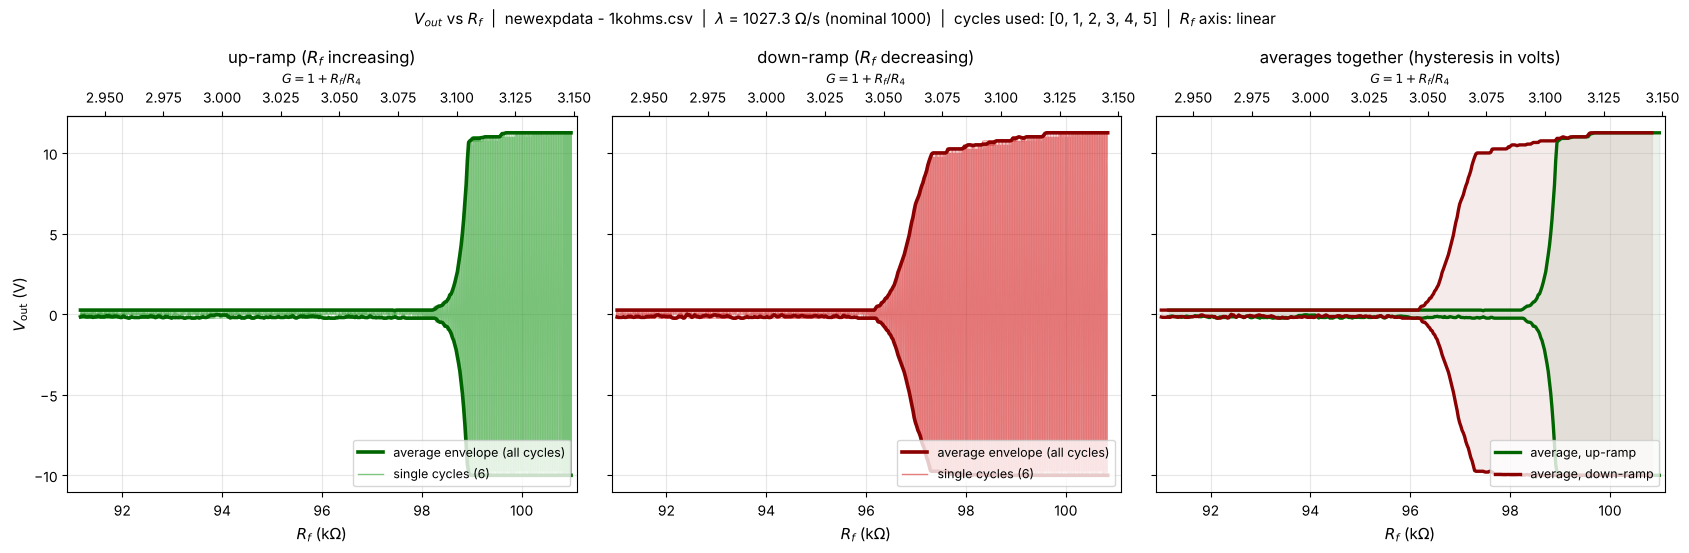

In [2]:
import os, warnings, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d, minimum_filter1d
from scipy.stats import spearmanr, rankdata
os.makedirs(OUT_DIR, exist_ok=True)
ONLY_LAMBDAS = C6_ONLY_LAMBDAS

COL_UP, COL_DN = "tab:green", "tab:red"


# ---------------- helpers (identical to Code 1 / Code 4) ----------------
def load_new(path):
    df = pd.read_csv(path)
    t_raw = df.iloc[:, 0].to_numpy(float)
    trig = df.iloc[:, 1].to_numpy(float)
    v = df.iloc[:, 2].to_numpy(float)
    n = len(v)
    dt = (t_raw[-1] - t_raw[0]) / (n - 1)
    return t_raw[0] + dt * np.arange(n), trig, v, dt


def runmax(x, n, side):
    o = (n - 1) // 2 if side == "back" else -(n // 2)
    return maximum_filter1d(x, n, origin=o, mode="nearest")


def k_lin(t, t0, tau, sph, top):
    u = ((np.asarray(t, float) - t0) / tau) % (2 * sph)
    return np.clip(np.minimum(u + 0.5, top + sph - 0.5 - u), 0, top)


def tap_exact(t, t0, tau, sph, top):
    u = ((np.asarray(t, float) - t0) / tau) % (2 * sph)
    up = np.minimum(np.floor(u) + 1, top)
    down = np.maximum(top - 1 - np.floor(u - sph), 0)
    return np.where(u < sph, up, down)


def find_file(run):
    for p in [run.file_path, os.path.join(DATA_FOLDER, run.file)]:
        if isinstance(p, str) and os.path.exists(p):
            return p
    raise FileNotFoundError(f"Raw file for lambda = {run.lambda_nominal:g} not found: tried {run.file_path!r} "
                            f"and {os.path.join(DATA_FOLDER, run.file)!r}. Set DATA_FOLDER.")


# ---------------- per-run computation ----------------
def build(run):
    t, trig, v, dt = load_new(find_file(run))
    period = run.osc_period_ms / 1e3
    w = max(3, int(round(2 * period / dt)))
    amp = 0.5 * (maximum_filter1d(v, w) - minimum_filter1d(v, w))
    on = amp > 0.05 * np.percentile(amp, 99)
    v = v - np.median(v[~on])                                   # same baseline as Code 1

    nW = max(3, int(round(run.ENV_WINDOW / dt)))
    pos, neg = np.clip(v, 0, None), np.clip(-v, 0, None)
    env_hi = np.minimum(runmax(pos, nW, "back"), runmax(pos, nW, "fwd"))      # upper envelope (>= 0)
    env_lo = -np.minimum(runmax(neg, nW, "back"), runmax(neg, nW, "fwd"))     # lower envelope (<= 0)

    sph, nsteps = int(run.STEPS_PER_HALF), int(run.N_STEPS)
    top = min(sph, nsteps)
    tau, t0 = run.tau_measured_ms / 1e3, run.t0_s
    T = 2 * sph * tau
    step_R = run.DELTA_R / nsteps
    k = k_lin(t, t0, tau, sph, top) if R_AXIS == "linear" else tap_exact(t, t0, tau, sph, top)
    R = (run.R0 + step_R * k) / 1e3                                            # kOhm
    u = ((t - t0) / tau) % (2 * sph)
    up = u < sph
    cyc = np.floor((t - t0) / T).astype(int)
    n_cyc = int(np.ceil((t[-1] - t0) / T)) if INCLUDE_PARTIAL else int(np.floor((t[-1] - t0) / T))
    cycles = [c for c in range(n_cyc) if c not in C6_SKIP_CYCLES and np.any(cyc == c)]

    R_min, R_max = run.R0 / 1e3, (run.R0 + step_R * top) / 1e3
    edges = np.linspace(R_min, R_max + 1e-9, N_BINS + 1)
    Rc = 0.5 * (edges[1:] + edges[:-1])

    def binned(mask, y):
        idx = np.clip(np.digitize(R[mask], edges) - 1, 0, N_BINS - 1)
        cnt = np.bincount(idx, minlength=N_BINS)
        s = np.bincount(idx, weights=y[mask], minlength=N_BINS)
        out = np.full(N_BINS, np.nan)
        out[cnt > 0] = s[cnt > 0] / cnt[cnt > 0]
        return out

    per = {"up": [], "down": []}
    for c in cycles:
        m = cyc == c
        for name, br in (("up", up), ("down", ~up)):
            mm = m & br
            per[name].append(dict(cycle=c, R=R[mm], v=v[mm], hi=binned(mm, env_hi), lo=binned(mm, env_lo)))
    def mean_over_cycles(key, name):
        if not per[name]:
            return np.full(N_BINS, np.nan)
        arr = np.array([p[key] for p in per[name]])
        n = np.sum(np.isfinite(arr), axis=0)
        out = np.full(N_BINS, np.nan)
        out[n > 0] = np.nansum(arr[:, n > 0], axis=0) / n[n > 0]       # average of the cycles that have data there
        return out
    avg = {name: dict(hi=mean_over_cycles("hi", name), lo=mean_over_cycles("lo", name)) for name in per}
    return dict(run=run, Rc=Rc, per=per, avg=avg, cycles=cycles, R_min=R_min, R_max=R_max)


# ---------------- plotting ----------------
def plot_run(B):
    run, Rc = B["run"], B["Rc"]
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), sharey=True)
    for ax, name, col, title in [(axes[0], "up", COL_UP, "up-ramp ($R_f$ increasing)"),
                                 (axes[1], "down", COL_DN, "down-ramp ($R_f$ decreasing)")]:
        for p in B["per"][name]:
            if SHOW_RAW and len(p["R"]):
                step = max(1, len(p["R"]) // MAX_RAW_POINTS)
                ax.plot(p["R"][::step], p["v"][::step], color=col, lw=0.25, alpha=0.18)
            if SHOW_CYCLE_ENVELOPES:
                ax.plot(Rc, p["hi"], color=col, lw=0.9, alpha=0.45)
                ax.plot(Rc, p["lo"], color=col, lw=0.9, alpha=0.45)
        dark = "darkgreen" if name == "up" else "darkred"
        ax.plot(Rc, B["avg"][name]["hi"], color=dark, lw=2.6, label="average envelope (all cycles)")
        ax.plot(Rc, B["avg"][name]["lo"], color=dark, lw=2.6)
        ax.plot([], [], color=col, lw=1, alpha=0.6, label=f"single cycles ({len(B['per'][name])})")
        ax.set_title(title, fontsize=12)
        ax.set_xlabel(r"$R_f$ (k$\Omega$)", fontsize=11)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9, loc="lower right")
    axes[0].set_ylabel(r"$V_{\mathrm{out}}$ (V)", fontsize=11)

    ax = axes[2]
    for name, dark, lab in [("up", "darkgreen", "up-ramp"), ("down", "darkred", "down-ramp")]:
        ax.plot(Rc, B["avg"][name]["hi"], color=dark, lw=2.4, label=f"average, {lab}")
        ax.plot(Rc, B["avg"][name]["lo"], color=dark, lw=2.4)
        ax.fill_between(Rc, B["avg"][name]["lo"], B["avg"][name]["hi"], color=dark, alpha=0.08)
    ax.set_title("averages together (hysteresis in volts)", fontsize=12)
    ax.set_xlabel(r"$R_f$ (k$\Omega$)", fontsize=11)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9, loc="lower right")
    R4 = run.R4
    for a in axes:
        a.set_xlim(B["R_min"] - 0.1, B["R_max"] + 0.1)
        sec = a.secondary_xaxis("top", functions=(lambda r: 1 + r * 1e3 / R4, lambda g: (g - 1) * R4 / 1e3))
        sec.set_xlabel(r"$G = 1 + R_f/R_4$", fontsize=9)
    fig.suptitle(f"$V_{{out}}$ vs $R_f$  |  {run.file}  |  $\\lambda$ = {run.lambda_measured:.1f} $\\Omega$/s "
                 f"(nominal {run.lambda_nominal:g})  |  cycles used: {B['cycles']}  |  $R_f$ axis: {R_AXIS}",
                 fontsize=11)
    plt.tight_layout()
    # fig.savefig(f"vout_vs_R_lambda_{run.lambda_nominal:g}.png", dpi=150)    # UNCOMMENT TO SAVE
    plt.savefig(os.path.join(OUT_DIR, f'code6_{len(plt.get_fignums())}_{id(plt.gcf())}.png'), dpi=110); plt.show()


def plot_all(Bs):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharey=True)
    cols = plt.cm.viridis(np.linspace(0, 0.9, len(Bs)))
    for B, c in zip(Bs, cols):
        lab = f"$\\lambda$ = {B['run'].lambda_measured:.0f} $\\Omega$/s"
        axes[0].plot(B["Rc"], B["avg"]["up"]["hi"], color=c, lw=2, label=lab)
        axes[1].plot(B["Rc"], B["avg"]["down"]["hi"], color=c, lw=2, label=lab)
    for ax, title in [(axes[0], "up-ramp: average upper envelope"), (axes[1], "down-ramp: average upper envelope")]:
        ax.set_title(title, fontsize=12)
        ax.set_xlabel(r"$R_f$ (k$\Omega$)", fontsize=11)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(r"$V_{\mathrm{out}}$ envelope (V)", fontsize=11)
    axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.tight_layout()
    # fig.savefig("vout_vs_R_all_lambdas.png", dpi=150)                        # UNCOMMENT TO SAVE
    plt.savefig(os.path.join(OUT_DIR, f'code6_{len(plt.get_fignums())}_{id(plt.gcf())}.png'), dpi=110); plt.show()


# ---------------- run ----------------
master = pd.read_csv(MASTER_CSV)
runs = master.groupby("lambda_nominal", as_index=False).first().sort_values("lambda_nominal")
if C6_ONLY_LAMBDAS:
    runs = runs[runs.lambda_nominal.isin(C6_ONLY_LAMBDAS)]
runs = runs.reset_index(drop=True)

built = []
with plt.style.context("default"):
    for _, run in runs.iterrows():
        try:
            B = build(run)
        except Exception as err:
            print(f"lambda = {run.lambda_nominal:g}: skipped ({err})")
            continue
        built.append(B)
        print(f"lambda = {run.lambda_nominal:g}: cycles used {B['cycles']}")
        plot_run(B)
    if len(built) > 1:
        plot_all(built)

## Part (b): lag between the top of the ramp and the burst, cycle by cycle

EVENT = t50_up, REFERENCE = top_start   (lag > 0: burst after the resistance maximum)

 lambda_nominal  n_cycles                                          lags_ms  lag_mean_ms  lag_std_ms  lag_mean_steps  always_increasing  slope_ms_per_cycle  slope_se_ms  slope_steps_per_cycle  spearman_rho  spearman_p
          100.0         5 -29928.7, -29503.5, -28974.3, -28758.5, -28381.9   -29109.386     611.811          -9.293               True             383.867       28.117                  0.123           1.0       0.017
          150.0         5 -18248.0, -18171.7, -18136.6, -17957.5, -17840.5   -18070.859     167.175          -8.645               True             102.920       13.982                  0.049           1.0       0.017
          200.0         5 -12896.2, -12952.0, -12935.3, -12949.2, -12936.3   -12933.785      22.328          -8.254              False              -7.747        6.817                 -0.005          -0.3       0.683
          250.0         5 -10110.9, -10093.5,

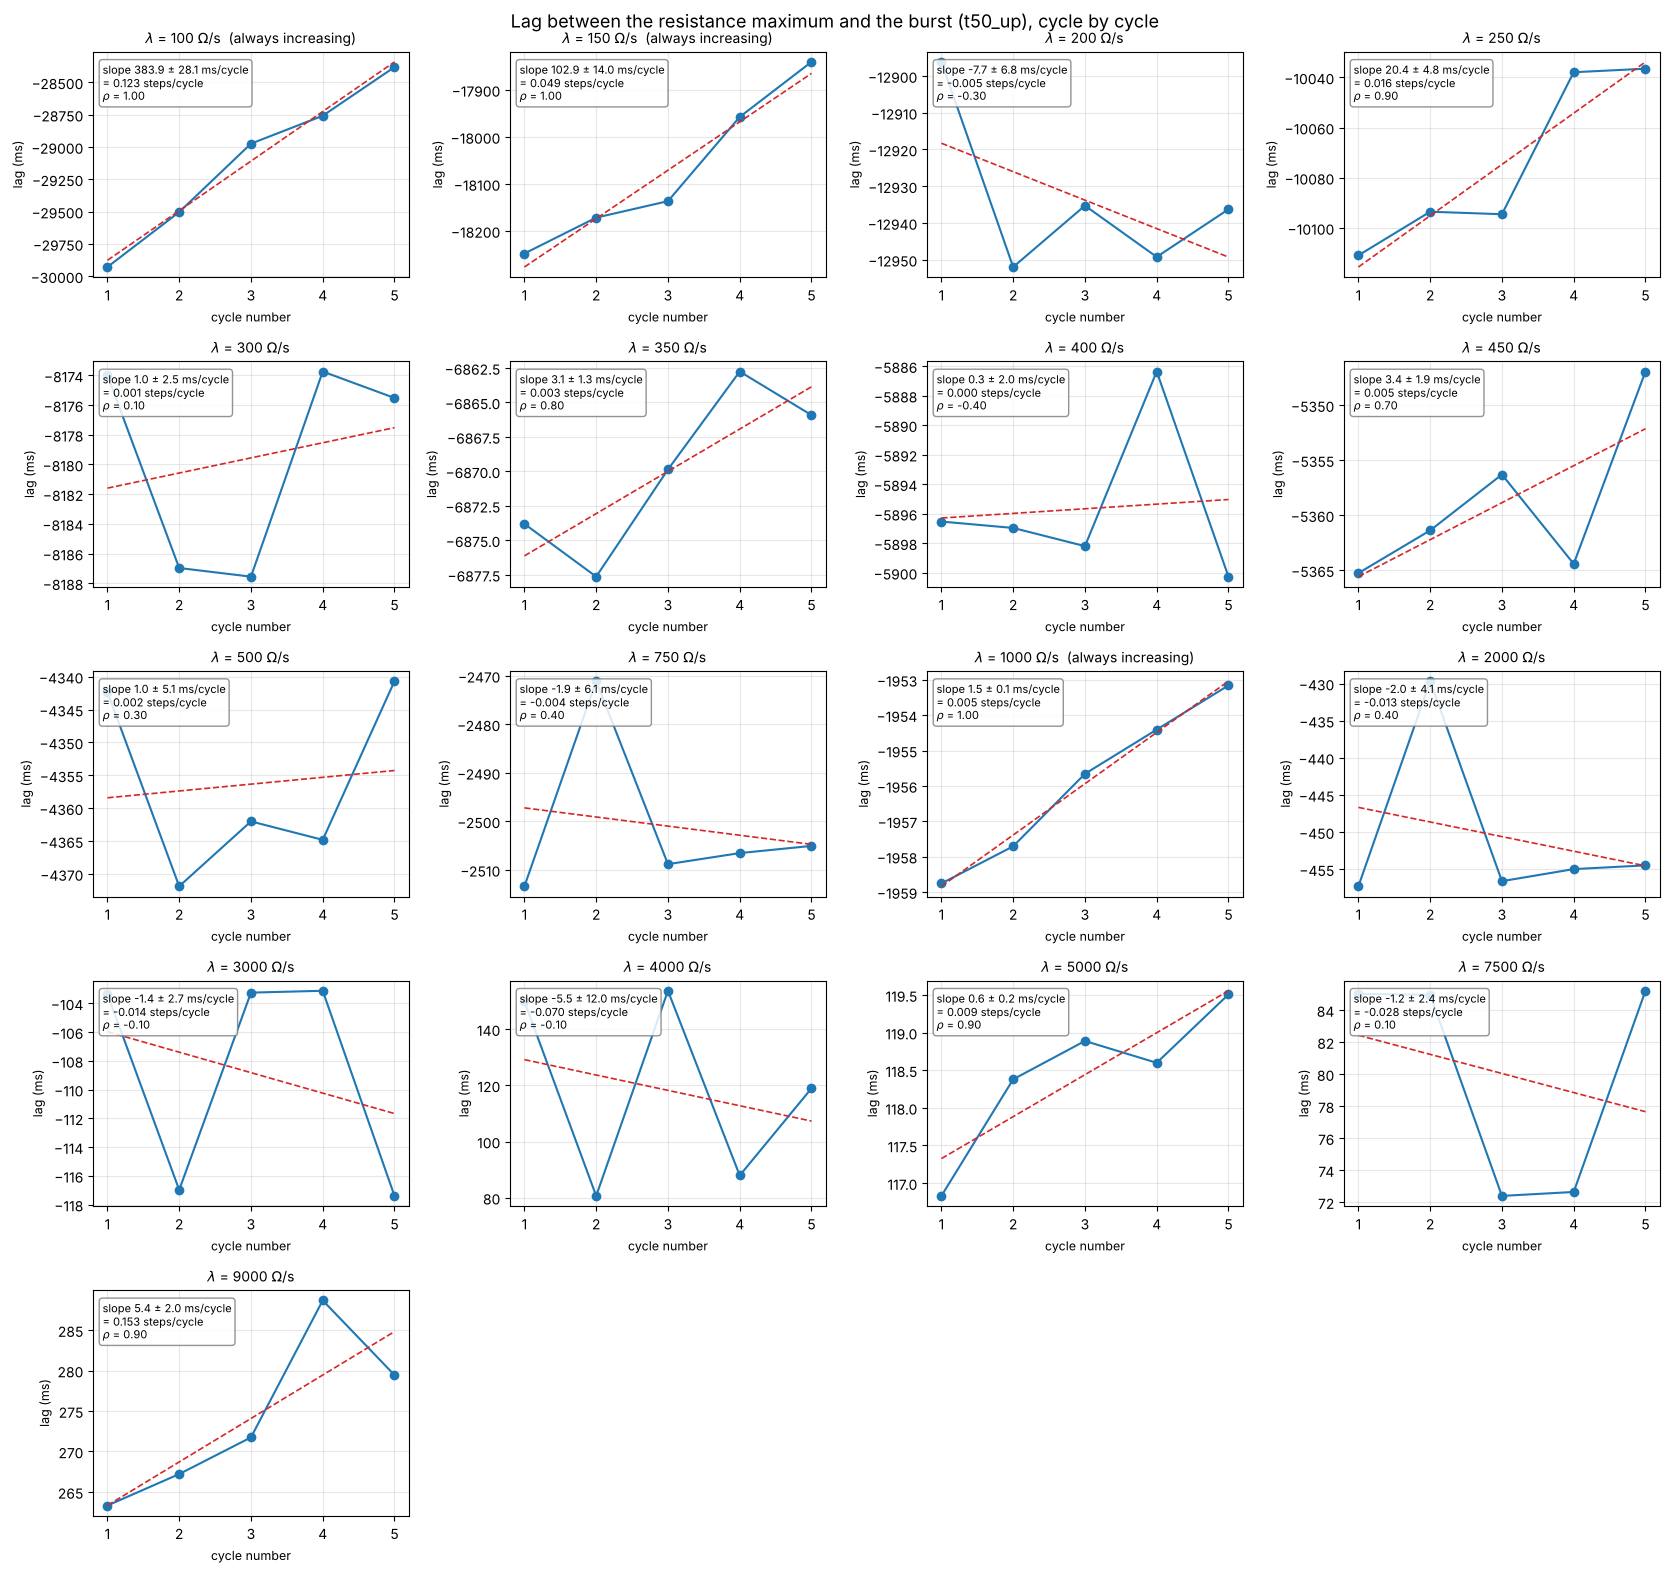

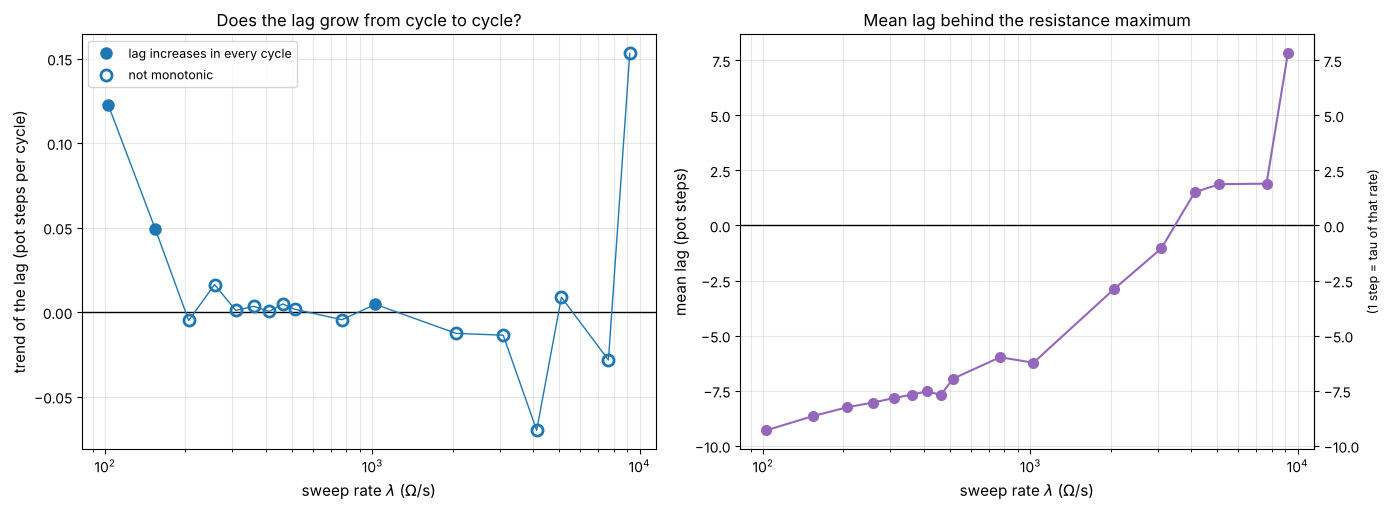

In [3]:
def exact_spearman_p(x, y):
    """Two-sided p-value of Spearman's rho by checking every possible order (exact for small n;
    scipy's default formula is far too optimistic for 5 points)."""
    n = len(x)
    if n < 3 or n > 8:
        return np.nan
    rx, ry = rankdata(x), rankdata(y)
    def rho(a, b):
        a, b = a - a.mean(), b - b.mean()
        d = np.sqrt((a * a).sum() * (b * b).sum())
        return (a * b).sum() / d if d > 0 else 0.0
    r0 = abs(rho(rx, ry))
    perms = list(itertools.permutations(ry))
    return sum(abs(rho(rx, np.array(p))) >= r0 - 1e-12 for p in perms) / len(perms)


def _as_bool(s):
    if s.dtype == bool:
        return s
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


m = pd.read_csv(MASTER_CSV)
if C7_ONLY_LAMBDAS:
    m = m[m.lambda_nominal.isin(C7_ONLY_LAMBDAS)]
m = m[m[EVENT].notna() & ~m.cycle.isin(C7_SKIP_CYCLES)].copy()
if "warmup" in m.columns:                              # simulations in cycle mode: drop warm-up cycles
    m = m[~_as_bool(m.warmup)]

sph = m.STEPS_PER_HALF.astype(float)
top = np.minimum(sph, m.N_STEPS.astype(float))
tau = m.tau_measured_ms.astype(float) / 1e3
u_ref = (top - 1 + sph) / 2 if REFERENCE == "top_centre" else (top - 1)      # 31 or 30 for the 32-tap pot
m["t_top"] = m.t0_s + (2 * sph * m.cycle + u_ref) * tau
m["lag_ms"] = (m[EVENT] - m.t_top) * 1e3
m["lag_steps"] = m.lag_ms / m.tau_measured_ms                                 # lag in units of one pot step

rows = []
for lam, g in m.groupby("lambda_nominal"):
    g = g.sort_values("cycle")
    c, L = g.cycle.to_numpy(float), g.lag_ms.to_numpy(float)
    tau_ms = g.tau_measured_ms.iloc[0]
    slope = se = rho = p = np.nan
    if len(c) >= 3:
        (slope, icpt), cov = np.polyfit(c, L, 1, cov=True) if len(c) > 3 else (np.polyfit(c, L, 1), None)
        if cov is not None:
            se = np.sqrt(cov[0, 0])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            rho = spearmanr(c, L)[0]
        p = exact_spearman_p(c, L)
    elif len(c) == 2:
        slope = (L[1] - L[0]) / (c[1] - c[0])
    rows.append(dict(lambda_nominal=lam, lambda_measured=g.lambda_measured.iloc[0], tau_ms=tau_ms,
                     n_cycles=len(c), lags_ms=", ".join(f"{x:.1f}" for x in L),
                     lag_mean_ms=L.mean(), lag_std_ms=L.std(ddof=1) if len(L) > 1 else np.nan,
                     lag_mean_steps=L.mean() / tau_ms,
                     always_increasing=bool(len(L) > 1 and np.all(np.diff(L) > 0)),
                     always_decreasing=bool(len(L) > 1 and np.all(np.diff(L) < 0)),
                     slope_ms_per_cycle=slope, slope_se_ms=se, slope_steps_per_cycle=slope / tau_ms,
                     spearman_rho=rho, spearman_p=p))
summary = pd.DataFrame(rows).sort_values("lambda_nominal").reset_index(drop=True)

pd.set_option("display.width", 250)
print(f"EVENT = {EVENT}, REFERENCE = {REFERENCE}   (lag > 0: burst after the resistance maximum)\n")
print(summary[["lambda_nominal", "n_cycles", "lags_ms", "lag_mean_ms", "lag_std_ms", "lag_mean_steps",
               "always_increasing", "slope_ms_per_cycle", "slope_se_ms", "slope_steps_per_cycle",
               "spearman_rho", "spearman_p"]].round(3).to_string(index=False))
print("\nNotes: spearman_p is exact (all orders checked). With 5 cycles only a perfect order (rho = +-1) gives "
      "p < 0.05 (p = 2/120 = 0.017); "
      "a slope is 'real' only if it is clearly larger than about 2 x slope_se.\n"
      "One pot step lasts tau_ms: lags that differ by about one tau come from the staircase, not from drift.")
# summary.to_csv("cycle_lag_summary.csv", index=False)                       # UNCOMMENT TO SAVE THE TABLE

with plt.style.context("default"):
    # ---- Figure 1: lag vs cycle number, one panel per rate ----
    lams = summary.lambda_nominal.tolist()
    n = len(lams)
    rows_ = int(np.ceil(n / N_COLS))
    fig, axes = plt.subplots(rows_, N_COLS, figsize=(4.2 * N_COLS, 3.2 * rows_), squeeze=False)
    for ax, lam in zip(axes.flat, lams):
        g = m[m.lambda_nominal == lam].sort_values("cycle")
        s = summary[summary.lambda_nominal == lam].iloc[0]
        ax.plot(g.cycle + 1, g.lag_ms, "o-", color="tab:blue", ms=6)
        if np.isfinite(s.slope_ms_per_cycle) and s.n_cycles >= 2:
            cc = np.array([g.cycle.min(), g.cycle.max()], float)
            ax.plot(cc + 1, s.lag_mean_ms + s.slope_ms_per_cycle * (cc - g.cycle.mean()), "--", color="tab:red", lw=1.2)
        se_txt = f" ± {s.slope_se_ms:.1f}" if np.isfinite(s.slope_se_ms) else ""
        flag = "  (always increasing)" if s.always_increasing else ""
        ax.set_title(f"$\\lambda$ = {lam:g} $\\Omega$/s{flag}", fontsize=10)
        ax.text(0.03, 0.95, f"slope {s.slope_ms_per_cycle:.1f}{se_txt} ms/cycle\n"
                            f"= {s.slope_steps_per_cycle:.3f} steps/cycle\n$\\rho$ = {s.spearman_rho:.2f}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.85))
        ax.set_xlabel("cycle number", fontsize=9)
        ax.set_ylabel("lag (ms)", fontsize=9)
        ax.set_xticks(sorted((g.cycle + 1).unique()))
        ax.grid(alpha=0.3)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.suptitle(f"Lag between the resistance maximum and the burst ({EVENT}), cycle by cycle", fontsize=13)
    plt.tight_layout()
    # fig.savefig("cycle_lag_per_rate.png", dpi=150)                          # UNCOMMENT TO SAVE
    plt.savefig(os.path.join(OUT_DIR, f'code7_{id(plt.gcf())}.png'), dpi=110); plt.show()

    # ---- Figure 2: trend (slope) and mean lag vs rate ----
    x = summary[X_AXIS].to_numpy(float)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
    inc = summary.always_increasing.to_numpy(bool)
    a1.axhline(0, color="k", lw=1)
    a1.plot(x, summary.slope_steps_per_cycle, "-", color="tab:blue", lw=1)
    a1.plot(x[inc], summary.slope_steps_per_cycle[inc], "o", color="tab:blue", ms=8,
            label="lag increases in every cycle")
    a1.plot(x[~inc], summary.slope_steps_per_cycle[~inc], "o", ms=8, mfc="none", mec="tab:blue", mew=2,
            label="not monotonic")
    a1.set_xscale("log")
    a1.set_xlabel(r"sweep rate $\lambda$ ($\Omega$/s)", fontsize=11)
    a1.set_ylabel("trend of the lag (pot steps per cycle)", fontsize=11)
    a1.set_title("Does the lag grow from cycle to cycle?", fontsize=12)
    a1.grid(alpha=0.3, which="both")
    a1.legend(fontsize=9)

    a2.axhline(0, color="k", lw=1)
    a2.plot(x, summary.lag_mean_steps, "o-", color="tab:purple", ms=7)
    a2.set_xscale("log")
    a2.set_xlabel(r"sweep rate $\lambda$ ($\Omega$/s)", fontsize=11)
    a2.set_ylabel("mean lag (pot steps)", fontsize=11)
    a2.set_title("Mean lag behind the resistance maximum", fontsize=12)
    a2.grid(alpha=0.3, which="both")
    sec = a2.secondary_yaxis("right")
    sec.set_ylabel("(1 step = tau of that rate)", fontsize=9)
    plt.tight_layout()
    # fig.savefig("cycle_lag_summary.png", dpi=150)                           # UNCOMMENT TO SAVE
    plt.savefig(os.path.join(OUT_DIR, f'code7_{id(plt.gcf())}.png'), dpi=110); plt.show()

## Check

Supplementary notebook: no number in the report is taken from it. For the report's data, part (b) shows a monotonic drift of the lag only at the two slowest rates: at 100 and 150 $\Omega$/s the lag grows over the five cycles by about 0.12 and 0.05 potentiometer steps per cycle (exact Spearman $p = 0.017$). At every other rate there is no monotonic trend. At 100 $\Omega$/s the drift is about 40 $\Omega$ per cycle in resistance, which is the size of that run's cycle-to-cycle spread in Table A.1.

## Using your own data

Use the master table and raw files of your own runs (notebook 05). Part (a) finds each raw file from the `file` column of the master and `DATA_FOLDER`.